In [1]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv("gold_price_X_Y_dataset.csv")
print(df)

      X        Y
0     1  5284.10
1     2  5313.62
2     3  5400.19
3     4  5481.40
4     5  5433.28
..  ...      ...
95   96  6857.12
96   97  6968.22
97   98  7003.36
98   99  7032.65
99  100  7065.19

[100 rows x 2 columns]


In [5]:
#tast 1
print(df.head())


   X        Y
0  1  5284.10
1  2  5313.62
2  3  5400.19
3  4  5481.40
4  5  5433.28


In [6]:
print(df.tail())

      X        Y
95   96  6857.12
96   97  6968.22
97   98  7003.36
98   99  7032.65
99  100  7065.19


In [7]:
print("Shape:", df.shape)

Shape: (100, 2)


In [8]:
print("Columns:", df.columns)

Columns: Index(['X', 'Y'], dtype='object')


In [9]:
print(df.dtypes)

X      int64
Y    float64
dtype: object


In [10]:
print(df.isnull().sum())

X    0
Y    0
dtype: int64


In [11]:
#TASK 2
# Separate input and output

X = df[["X"]]
y = df["Y"]

print("Input variable (X):")
display(X.head())

print("Output variable (y):")
display(y.head())

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)



Input variable (X):


,X
0,1
1,2
2,3
3,4
4,5


Output variable (y):


0    5284.10
1    5313.62
2    5400.19
3    5481.40
4    5433.28
Name: Y, dtype: float64

Shape of X: (100, 1)
Shape of y: (100,)


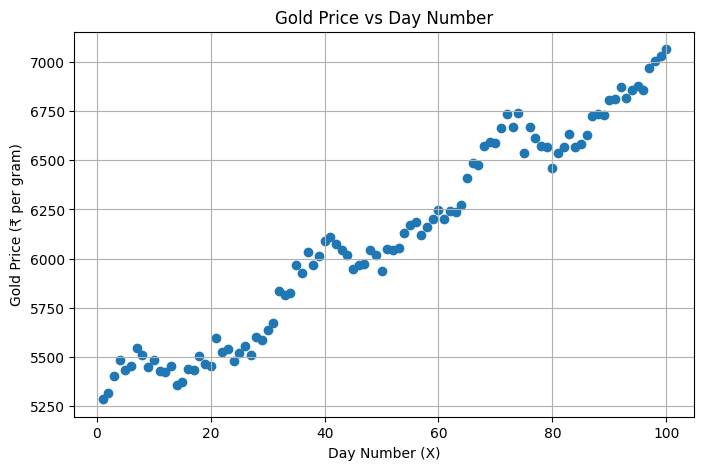

In [12]:
#TASK 3
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(X["X"], y)

plt.title("Gold Price vs Day Number")
plt.xlabel("Day Number (X)")
plt.ylabel("Gold Price (₹ per gram)")
plt.grid(True)

plt.show()


In [13]:
#TASK 4
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train rows:", len(X_train))
print("X_test rows:", len(X_test))
print("y_train rows:", len(y_train))
print("y_test rows:", len(y_test))



X_train rows: 80
X_test rows: 20
y_train rows: 80
y_test rows: 20


In [14]:
#TASK 5
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display intercept and coefficient
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])




Intercept: 5224.894271013003
Coefficient: 17.45939814467626


In [15]:
#TASK 6

# Predict prices for testing data
y_pred = model.predict(X_test)

# Compare actual and predicted prices
results = pd.DataFrame({
    "Day Number": X_test["X"].values,
    "Actual Gold Price": y_test.values,
    "Predicted Gold Price": y_pred
})

display(results.round(2))

# Predict gold price for day 101
new_data = pd.DataFrame({"X": [101]})

predicted_price = model.predict(new_data)

print("Predicted gold price for day 101: ₹",
      round(predicted_price[0], 2))



,Day Number,Actual Gold Price,Predicted Gold Price
0,84,6565.66,6691.48
1,54,6132.03,6167.70
2,71,6664.53,6464.51
3,46,5968.95,6028.03
4,45,5947.91,6010.57
5,40,6090.43,5923.27
6,23,5541.09,5626.46
7,81,6537.08,6639.11
8,11,5430.00,5416.95
9,1,5284.10,5242.35


Predicted gold price for day 101: ₹ 6988.29


In [16]:
#TASK 7
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Calculate RMSE
rmse = mse ** 0.5

# Calculate R2 score
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))



MAE: 77.12
MSE: 9912.24
RMSE: 99.56
R2 Score: 0.961


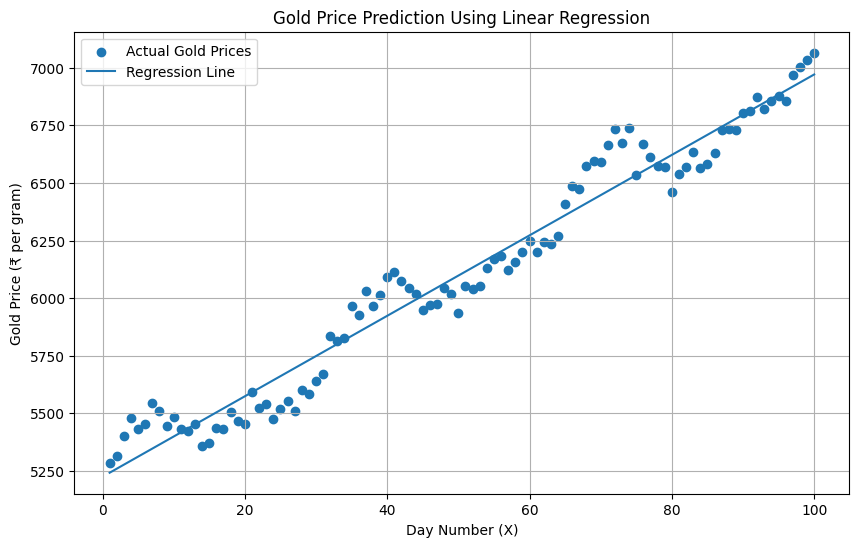

In [17]:
#TASK 8
import numpy as np
import matplotlib.pyplot as plt

# Predict prices for all X values
all_predictions = model.predict(X)

# Plot original data
plt.figure(figsize=(10, 6))
plt.scatter(X["X"], y, label="Actual Gold Prices")

# Sort X values so the regression line appears correctly
sorted_indices = np.argsort(X["X"].values)

sorted_X = X["X"].values[sorted_indices]
sorted_predictions = all_predictions[sorted_indices]

# Plot regression line
plt.plot(sorted_X, sorted_predictions,
         label="Regression Line")

plt.title("Gold Price Prediction Using Linear Regression")
plt.xlabel("Day Number (X)")
plt.ylabel("Gold Price (₹ per gram)")
plt.legend()
plt.grid(True)

plt.show()



In [18]:
#TASK 9
print(
    f"Predicted Y = {model.intercept_:.2f} "
    f"+ ({model.coef_[0]:.2f} × X)"
)

Predicted Y = 5224.89 + (17.46 × X)


In [19]:
#TASK 10
# Split data using 30% testing data
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Create and train a new model
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

# Predict test values
y_pred2 = model2.predict(X_test2)

# Calculate evaluation metrics
mae2 = mean_absolute_error(y_test2, y_pred2)
mse2 = mean_squared_error(y_test2, y_pred2)
rmse2 = mse2 ** 0.5
r22 = r2_score(y_test2, y_pred2)

print("Results with test_size = 0.3")
print("MAE:", round(mae2, 2))
print("MSE:", round(mse2, 2))
print("RMSE:", round(rmse2, 2))
print("R2 Score:", round(r22, 4))

print("\nComparison with test_size = 0.2")
print("MAE (0.2):", round(mae, 2))
print("MAE (0.3):", round(mae2, 2))
print("R2 (0.2):", round(r2, 4))
print("R2 (0.3):", round(r22, 4))



Results with test_size = 0.3
MAE: 85.28
MSE: 11401.06
RMSE: 106.78
R2 Score: 0.9576

Comparison with test_size = 0.2
MAE (0.2): 77.12
MAE (0.3): 85.28
R2 (0.2): 0.961
R2 (0.3): 0.9576
